# BIRDS CubeSat electrical power system

This notebook lists the four released satellites, loads one data collection of one satellite, and plots its battery voltage. It makes no diagnosis.

## 1. Released units

This step lists what `systems('birds_cubesat')` reports for the release.

In [1]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import pandas as pd

ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / 'fielddata').exists())
sys.path.insert(0, str(ROOT))
from fielddata import load, systems

released = systems('birds_cubesat')
display(released)

,unit,downloads,test_sheets,rows,first,last,observed_hours,chemistry,cells,cell_rated_mAh,cell_nominal_V,pack_nominal_Wh,source
0,NEPALISAT,3,0,3040,2020-11-09,2021-04-10,4.218056,NiMH,"6 (3 series, 2 parallel)",2000,1.2,14.4,"Jara et al. 2022, Section 2 and Table 2 (Enelo..."
1,RAAVANA,2,0,2159,2021-02-13,2021-03-11,2.995833,NiMH,"6 (3 series, 2 parallel)",2000,1.2,14.4,"Jara et al. 2022, Section 2 and Table 2 (Enelo..."
2,TSURU,40,2,25653,2021-03-28,2022-01-24,65.819250,NiMH,"6 (3 series, 2 parallel)",2000,1.2,14.4,"Jara et al. 2022, Section 2 and Table 2 (Enelo..."
3,UGUISU,3,0,3270,2020-10-23,2021-04-10,4.523611,NiMH,"6 (3 series, 2 parallel)",2000,1.2,14.4,"Jara et al. 2022, Section 2 and Table 2 (Enelo..."


Each row is one satellite with its downloads, test sheets and first and last download date. Each sheet is one collection over one orbit.

## 2. One unit as released

This step loads one unit with the default `clean=False`, so every value is as released.

In [2]:
frame = load('birds_cubesat', unit='TSURU', sheet='March 28')
print(frame.shape)
display(frame.head())

(1095, 38)


,sheet,time_s,Tpy_raw,Tpy_C,Tpx_raw,Tpx_C,Tmz_raw,Tmz_C,Tmx_raw,Tmx_C,...,Imx_raw,Imx_mA,Ipz_raw,Ipz_mA,Vbat_raw,Vbat_V,Ibatt_raw,Ibatt_mA,Tbatt_raw,Tbatt_C
0,March 28,0.0,0676,4.63,0668,6.19,06C3,-3.91,06A7,-0.81,...,00,0.0,02,9.32,A1,4.1,07A1,280.91,A9,10.26
1,March 28,11.3,0679,4.30,066A,5.96,06C4,-4.02,06AB,-1.25,...,00,0.0,01,4.66,A1,4.1,079D,292.62,A9,10.26
2,March 28,22.6,067F,3.63,066F,5.41,06C7,-4.36,06AE,-1.58,...,00,0.0,01,4.66,A1,4.1,0789,351.19,A9,10.26
3,March 28,33.9,0683,3.19,0671,5.19,06CA,-4.69,06B2,-2.03,...,00,0.0,02,9.32,A1,4.1,0798,307.26,A9,10.26
4,March 28,45.2,0688,2.63,0673,4.97,06CD,-5.02,06B5,-2.36,...,00,0.0,01,4.66,A1,4.1,07A9,257.48,A9,10.26


One collection of TSURU, with the 37 columns named by position because header spelling varies between sheets. time_s counts seconds within the collection.

## 3. Signal ranges

This step summarises a few signals of the loaded unit.

In [3]:
display(frame[['Vbat_V', 'Ibatt_mA', 'Tbatt_C']].describe().T)

,count,mean,std,min,25%,50%,75%,max
Vbat_V,1095.0,4.108603,0.086956,3.92,4.04,4.12,4.20,4.20
Ibatt_mA,1095.0,33.937553,269.510092,-641.52,-131.99,-47.07,286.77,374.62
Tbatt_C,1095.0,8.250055,1.513311,5.67,6.82,8.73,9.50,10.65


These ranges are raw values as released, before any cleaning. The schema file next to the loader lists units and any sentinel codes.

## 4. A first look

This step plots one signal to show the shape of the data.

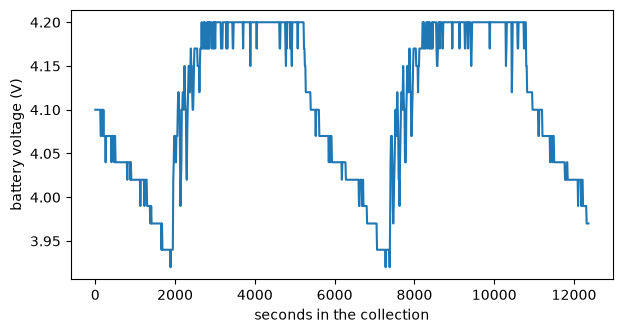

In [4]:
ax = frame.plot(x='time_s', y='Vbat_V', figsize=(7, 3.5), legend=False)
ax.set_xlabel('seconds in the collection')
ax.set_ylabel('battery voltage (V)')
plt.show()

Over this collection of about 3.4 hours TSURU's battery voltage stays between 3.92 and 4.20 V while the battery cycles with the orbit.